# Lab 03

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Lab Task 1: Dataset Loading and Visualization

Part A
Dataset loaded successfully
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  peri

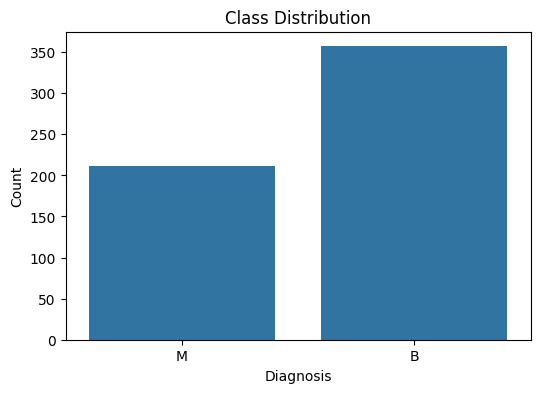

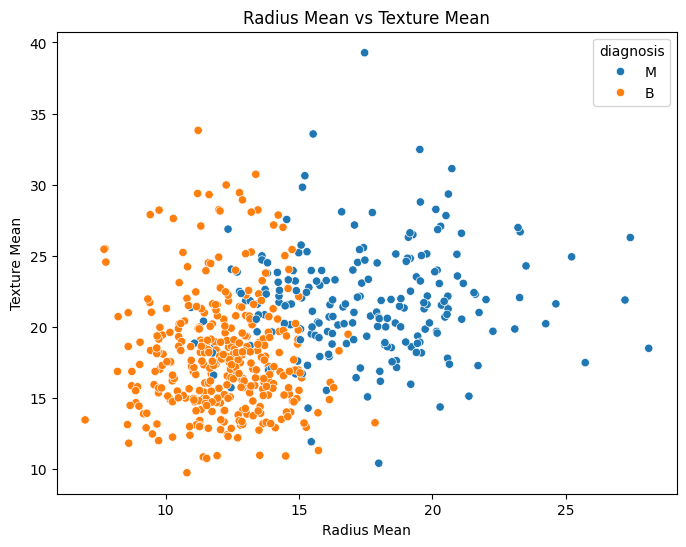


Part D
Feature shape: (569, 30)
Target shape: (569,)
Training features shape: (455, 30)
Testing features shape: (114, 30)
Training target shape: (455,)
Testing target shape: (114,)
Features prepared for model training
Scaled training features shape: (455, 30)
Scaled testing features shape: (114, 30)


In [ ]:
data = pd.read_csv("data.csv")
print("Dataset loaded successfully")
print(data.head())
print("Dataset shape:", data.shape)
print("Features:")
print(data.columns.tolist())
print("Target variable: diagnosis")
print("Missing values:")
print(data.isnull().sum())
print("Class distribution:")
print(data["diagnosis"].value_counts())
plt.figure(figsize=(6,4))
sns.countplot(x="diagnosis",data=data)
plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()
plt.figure(figsize=(8,6))
sns.scatterplot(x="radius_mean",y="texture_mean",hue="diagnosis",data=data)
plt.title("Radius Mean vs Texture Mean")
plt.xlabel("Radius Mean")
plt.ylabel("Texture Mean")
plt.show()
X = data.drop(columns=["id","diagnosis","Unnamed: 32"],errors="ignore")
y = data["diagnosis"]
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Features prepared for model training")
print("Scaled training features shape:", X_train.shape)
print("Scaled testing features shape:", X_test.shape)

Lab Task 2: Basic Perceptron Implementation

Part A
Training data shape: (455, 30)
Testing data shape: (114, 30)

Part B
Initial weights: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
Initial bias: 0
Learning rate: 0.01

Part C
Epoch: 1
Training accuracy: 0.9736263736263736
Epoch: 2
Training accuracy: 0.9648351648351648
Epoch: 3
Training accuracy: 0.9758241758241758
Epoch: 4
Training accuracy: 0.9736263736263736
Epoch: 5
Training accuracy: 0.9736263736263736
Epoch: 6
Training accuracy: 0.978021978021978
Epoch: 7
Training accuracy: 0.978021978021978
Epoch: 8
Training accuracy: 0.9824175824175824
Epoch: 9
Training accuracy: 0.9802197802197802
Epoch: 10
Training accuracy: 0.9736263736263736
Epoch: 11
Training accuracy: 0.9802197802197802
Epoch: 12
Training accuracy: 0.9868131868131869
Epoch: 13
Training accuracy: 0.9846153846153847
Epoch: 14
Training accuracy: 0.9802197802197802
Epoch: 15
Training accuracy: 0.989010989010989
Epoch: 16
Training accuracy: 0.9846153846153847
Epoch: 17
Trai

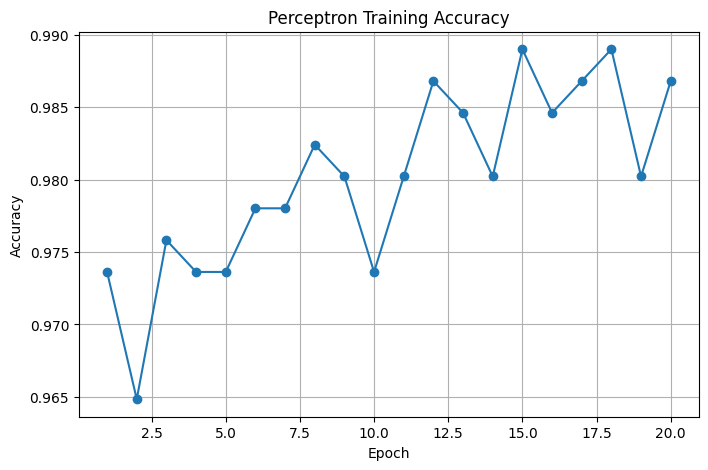

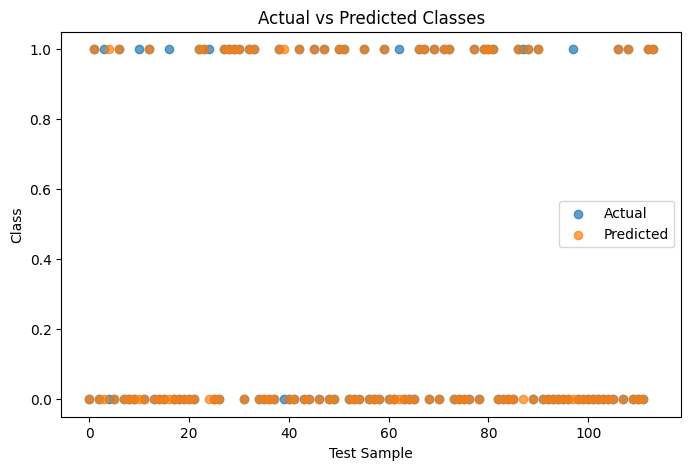

In [ ]:
data = pd.read_csv("data.csv")
X = data.drop(columns=["id","diagnosis","Unnamed: 32"],errors="ignore")
y = data["diagnosis"].map({"B":0,"M":1})
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
weights = np.zeros(X_train.shape[1])
bias = 0
learning_rate = 0.01
print("Initial weights:", weights)
print("Initial bias:", bias)
print("Learning rate:", learning_rate)
def predict(X):
    linear_output = np.dot(X,weights) + bias
    predictions = np.where(linear_output >= 0,1,0)
    return predictions
epochs = 20
accuracy_history = []
for epoch in range(epochs):
    for i in range(len(X_train)):
        prediction = predict(X_train[i])
        error = y_train.iloc[i] - prediction
        weights += learning_rate * error * X_train[i]
        bias += learning_rate * error
    train_predictions = predict(X_train)
    train_accuracy = np.mean(train_predictions == y_train.to_numpy())
    accuracy_history.append(train_accuracy)
    print("Epoch:", epoch + 1)
    print("Training accuracy:", train_accuracy)
test_predictions = predict(X_test)
test_accuracy = np.mean(test_predictions == y_test.to_numpy())
print("Test accuracy:", test_accuracy)
print("Test accuracy percentage:", test_accuracy * 100)
plt.figure(figsize=(8,5))
plt.plot(range(1,epochs + 1),accuracy_history,marker="o")
plt.title("Perceptron Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid()
plt.show()
plt.figure(figsize=(8,5))
plt.scatter(range(len(y_test)),y_test.to_numpy(),label="Actual",alpha=0.7)
plt.scatter(range(len(test_predictions)),test_predictions,label="Predicted",alpha=0.7)
plt.title("Actual vs Predicted Classes")
plt.xlabel("Test Sample")
plt.ylabel("Class")
plt.legend()
plt.show()


Lab Task 3: Perceptron Learning Curve and Weight Visualization

Part A
Training data shape: (455, 30)
Testing data shape: (114, 30)

Part B
Initial weights: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
Initial bias: 0
Learning rate: 0.01
Number of epochs: 20

Part C
Epoch: 1
Training error: 36
Epoch: 2
Training error: 21
Epoch: 3
Training error: 19
Epoch: 4
Training error: 13
Epoch: 5
Training error: 20
Epoch: 6
Training error: 14
Epoch: 7
Training error: 15
Epoch: 8
Training error: 14
Epoch: 9
Training error: 14
Epoch: 10
Training error: 17
Epoch: 11
Training error: 14
Epoch: 12
Training error: 10
Epoch: 13
Training error: 13
Epoch: 14
Training error: 19
Epoch: 15
Training error: 10
Epoch: 16
Training error: 15
Epoch: 17
Training error: 13
Epoch: 18
Training error: 8
Epoch: 19
Training error: 8
Epoch: 20
Training error: 19

Part D
Final test accuracy: 0.9210526315789473
Final test accuracy percentage: 92.10526315789474

Part E
Final weights:
Weight 1 : 0.0008638700836603062
Weight 2 : -0.028431097499

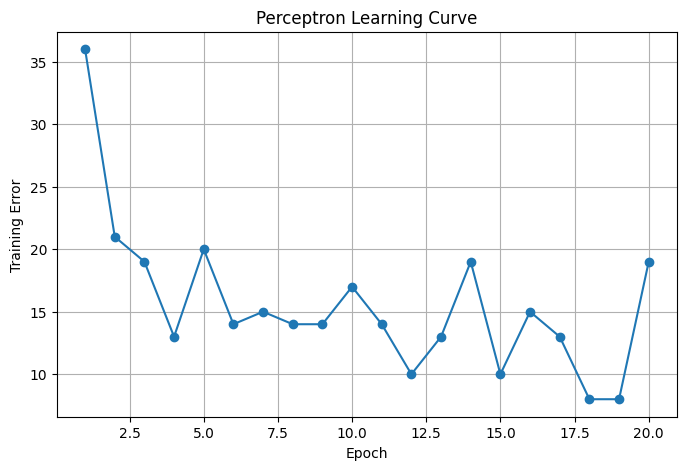


Part G


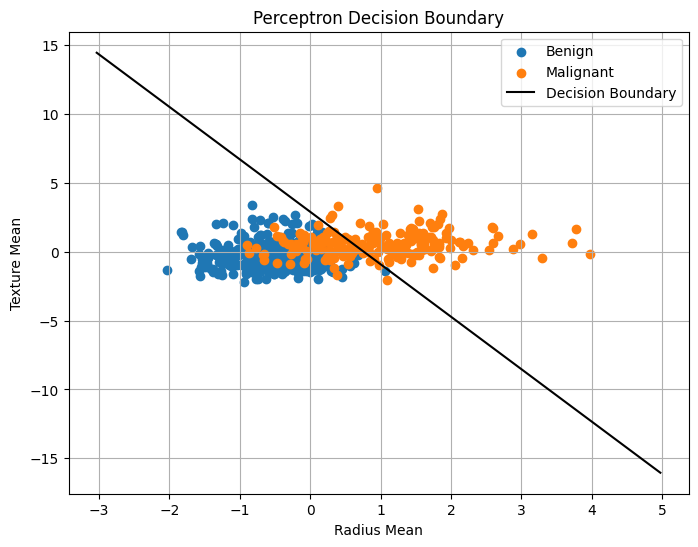

In [ ]:
data = pd.read_csv("data.csv")
X = data.drop(columns=["id","diagnosis","Unnamed: 32"],errors="ignore")
y = data["diagnosis"].map({"B":0,"M":1})
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
weights = np.zeros(X_train.shape[1])
bias = 0
learning_rate = 0.01
epochs = 20
print("Initial weights:", weights)
print("Initial bias:", bias)
print("Learning rate:", learning_rate)
print("Number of epochs:", epochs)
def predict(X):
    linear_output = np.dot(X,weights) + bias
    predictions = np.where(linear_output >= 0,1,0)
    return predictions
error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i])
        error = y_train.iloc[i] - prediction
        weights += learning_rate * error * X_train[i]
        bias += learning_rate * error
        total_error += abs(error)
    error_history.append(total_error)
    print("Epoch:", epoch + 1)
    print("Training error:", total_error)
test_predictions = predict(X_test)
test_accuracy = np.mean(test_predictions == y_test.to_numpy())
print("Final test accuracy:", test_accuracy)
print("Final test accuracy percentage:", test_accuracy * 100)
print("Final weights:")
for i in range(len(weights)):
    print("Weight",i + 1,":",weights[i])
print("Final bias:",bias)
plt.figure(figsize=(8,5))
plt.plot(range(1,epochs + 1),error_history,marker="o")
plt.title("Perceptron Learning Curve")
plt.xlabel("Epoch")
plt.ylabel("Training Error")
plt.grid()
plt.show()
feature1 = "radius_mean"
feature2 = "texture_mean"
X_visual = data[[feature1,feature2]]
y_visual = data["diagnosis"].map({"B":0,"M":1})
visual_scaler = StandardScaler()
X_visual_scaled = visual_scaler.fit_transform(X_visual)
visual_weights = np.zeros(2)
visual_bias = 0
for epoch in range(epochs):
    for i in range(len(X_visual_scaled)):
        linear_output = np.dot(X_visual_scaled[i],visual_weights) + visual_bias
        prediction = 1 if linear_output >= 0 else 0
        error = y_visual.iloc[i] - prediction
        visual_weights += learning_rate * error * X_visual_scaled[i]
        visual_bias += learning_rate * error
x_min = X_visual_scaled[:,0].min() - 1
x_max = X_visual_scaled[:,0].max() + 1
y_min = X_visual_scaled[:,1].min() - 1
y_max = X_visual_scaled[:,1].max() + 1
x_values = np.linspace(x_min,x_max,100)
if visual_weights[1] != 0:
    y_values = -(visual_weights[0] * x_values + visual_bias) / visual_weights[1]
plt.figure(figsize=(8,6))
plt.scatter(X_visual_scaled[y_visual == 0,0],X_visual_scaled[y_visual == 0,1],label="Benign")
plt.scatter(X_visual_scaled[y_visual == 1,0],X_visual_scaled[y_visual == 1,1],label="Malignant")
plt.plot(x_values,y_values,color="black",label="Decision Boundary")
plt.title("Perceptron Decision Boundary")
plt.xlabel("Radius Mean")
plt.ylabel("Texture Mean")
plt.legend()
plt.grid()
plt.show()

Lab Task 4: Gaussian Weight Initialization

Part A
Training data shape: (455, 30)
Testing data shape: (114, 30)

Part B
Learning rate: 0.01
Number of epochs: 20

Part C
Default initialization training completed
Default final bias: 0.019999999999999997

Part D
Gaussian mean: 0
Gaussian standard deviation: 0.01
Initial Gaussian weights: [ 0.00496714 -0.00138264  0.00647689  0.0152303  -0.00234153 -0.00234137
  0.01579213  0.00767435 -0.00469474  0.0054256  -0.00463418 -0.0046573
  0.00241962 -0.0191328  -0.01724918 -0.00562288 -0.01012831  0.00314247
 -0.00908024 -0.01412304  0.01465649 -0.00225776  0.00067528 -0.01424748
 -0.00544383  0.00110923 -0.01150994  0.00375698 -0.00600639 -0.00291694]
Initial Gaussian bias: -0.006017066122293969
Gaussian initialization training completed
Gaussian final bias: 0.06398293387770604

Part E
Default initialization accuracy: 0.9210526315789473
Default initialization accuracy percentage: 92.10526315789474
Gaussian initialization accuracy: 0.9824561403508771
Gaussian initialization accuracy perce

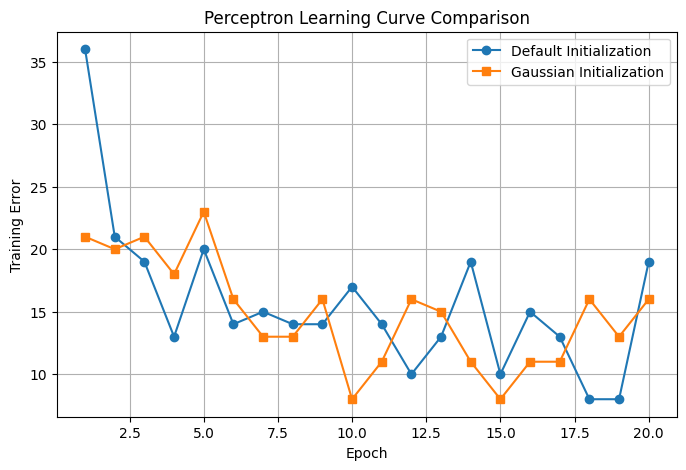


Part I


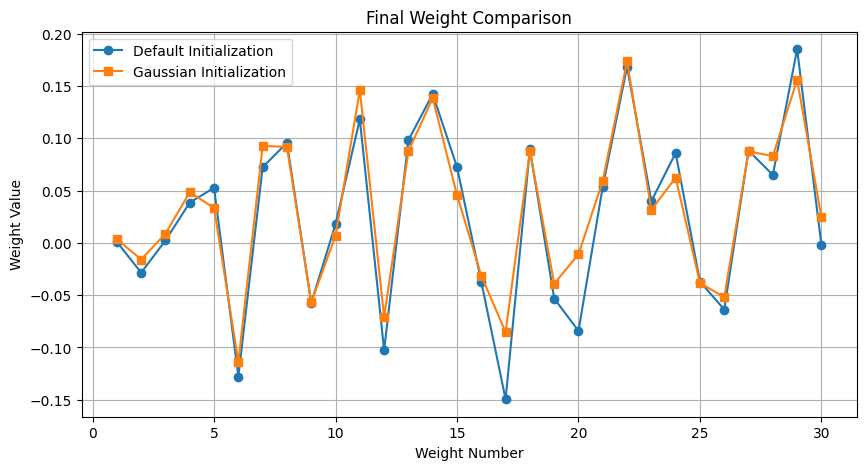


Part J


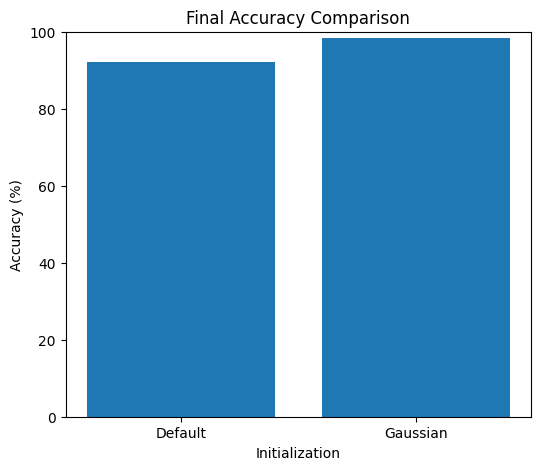

In [ ]:
data = pd.read_csv("data.csv")
X = data.drop(columns=["id","diagnosis","Unnamed: 32"],errors="ignore")
y = data["diagnosis"].map({"B":0,"M":1})
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training data shape:",X_train.shape)
print("Testing data shape:",X_test.shape)
learning_rate = 0.01
epochs = 20
def predict(X,weights,bias):
    linear_output = np.dot(X,weights) + bias
    predictions = np.where(linear_output >= 0,1,0)
    return predictions
print("Learning rate:",learning_rate)
print("Number of epochs:",epochs)
default_weights = np.zeros(X_train.shape[1])
default_bias = 0
default_error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],default_weights,default_bias)
        error = y_train.iloc[i] - prediction
        default_weights += learning_rate * error * X_train[i]
        default_bias += learning_rate * error
        total_error += abs(error)
    default_error_history.append(total_error)
print("Default initialization training completed")
print("Default final bias:",default_bias)
np.random.seed(42)
mean = 0
standard_deviation = 0.01
gaussian_weights = np.random.normal(mean,standard_deviation,X_train.shape[1])
gaussian_bias = np.random.normal(mean,standard_deviation)
gaussian_error_history = []
print("Gaussian mean:",mean)
print("Gaussian standard deviation:",standard_deviation)
print("Initial Gaussian weights:",gaussian_weights)
print("Initial Gaussian bias:",gaussian_bias)
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],gaussian_weights,gaussian_bias)
        error = y_train.iloc[i] - prediction
        gaussian_weights += learning_rate * error * X_train[i]
        gaussian_bias += learning_rate * error
        total_error += abs(error)
    gaussian_error_history.append(total_error)
print("Gaussian initialization training completed")
print("Gaussian final bias:",gaussian_bias)
default_predictions = predict(X_test,default_weights,default_bias)
gaussian_predictions = predict(X_test,gaussian_weights,gaussian_bias)
default_accuracy = np.mean(default_predictions == y_test.to_numpy())
gaussian_accuracy = np.mean(gaussian_predictions == y_test.to_numpy())
print("Default initialization accuracy:",default_accuracy)
print("Default initialization accuracy percentage:",default_accuracy * 100)
print("Gaussian initialization accuracy:",gaussian_accuracy)
print("Gaussian initialization accuracy percentage:",gaussian_accuracy * 100)
default_convergence_epoch = next((i + 1 for i,error in enumerate(default_error_history) if error == 0),epochs)
gaussian_convergence_epoch = next((i + 1 for i,error in enumerate(gaussian_error_history) if error == 0),epochs)
print("Default initialization convergence epoch:",default_convergence_epoch)
print("Gaussian initialization convergence epoch:",gaussian_convergence_epoch)
print("Final weights comparison:")
for i in range(len(default_weights)):
    print("Weight",i + 1,": Default =",default_weights[i],", Gaussian =",gaussian_weights[i])
print("Default final bias:",default_bias)
print("Gaussian final bias:",gaussian_bias)
plt.figure(figsize=(8,5))
plt.plot(range(1,epochs + 1),default_error_history,marker="o",label="Default Initialization")
plt.plot(range(1,epochs + 1),gaussian_error_history,marker="s",label="Gaussian Initialization")
plt.title("Perceptron Learning Curve Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Error")
plt.legend()
plt.grid()
plt.show()
weight_numbers = np.arange(1,len(default_weights) + 1)
plt.figure(figsize=(10,5))
plt.plot(weight_numbers,default_weights,marker="o",label="Default Initialization")
plt.plot(weight_numbers,gaussian_weights,marker="s",label="Gaussian Initialization")
plt.title("Final Weight Comparison")
plt.xlabel("Weight Number")
plt.ylabel("Weight Value")
plt.legend()
plt.grid()
plt.show()
plt.figure(figsize=(6,5))
models = ["Default","Gaussian"]
accuracies = [default_accuracy * 100,gaussian_accuracy * 100]
plt.bar(models,accuracies)
plt.title("Final Accuracy Comparison")
plt.xlabel("Initialization")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)
plt.show()

Lab Task 5: Xavier/Glorot Initialization

Part A
Training data shape: (455, 30)
Testing data shape: (114, 30)

Part B
Learning rate: 0.01
Number of epochs: 20

Part C
Number of input features: 30
Xavier initialization limit: 0.4472135954999579
Initial Xavier weights: [-0.11221473  0.40313113  0.20750169  0.08824283 -0.30766628 -0.30768785
 -0.39526203  0.3275179   0.09044002  0.18610577 -0.42880226  0.42030015
  0.29734574 -0.25729172 -0.2845844  -0.28317161 -0.17509106  0.02214283
 -0.06087023 -0.18673033  0.10004427 -0.32244649 -0.18591148 -0.1195296
 -0.0392922   0.25506913 -0.26861994  0.01273167  0.0826581  -0.40566708]
Initial Xavier bias: 0.09619103979270544

Part D
Epoch: 1
Training error: 50
Epoch: 2
Training error: 24
Epoch: 3
Training error: 21
Epoch: 4
Training error: 20
Epoch: 5
Training error: 19
Epoch: 6
Training error: 17
Epoch: 7
Training error: 17
Epoch: 8
Training error: 15
Epoch: 9
Training error: 13
Epoch: 10
Training error: 21
Epoch: 11
Training error: 18
Epoch: 12
Training error: 12
Epoch: 13
Training er

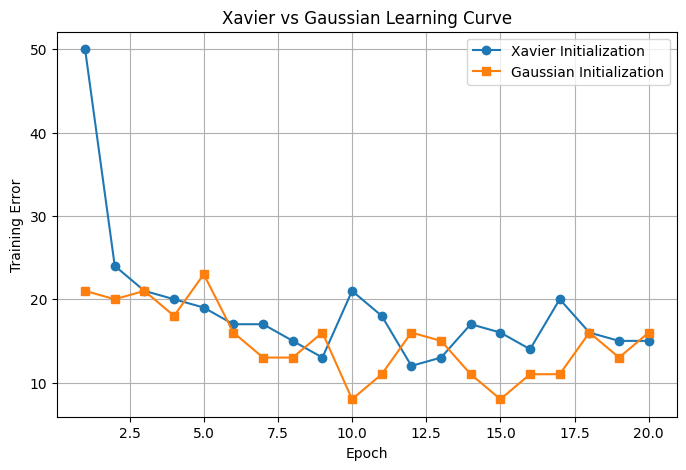


Part I


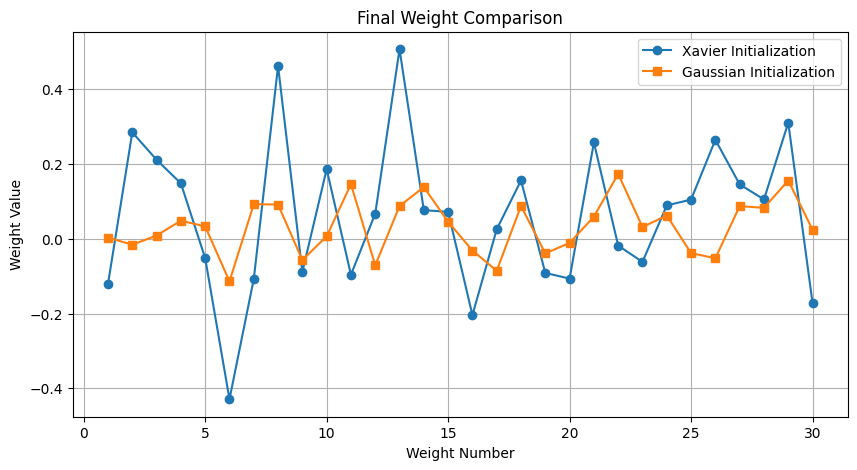


Part J


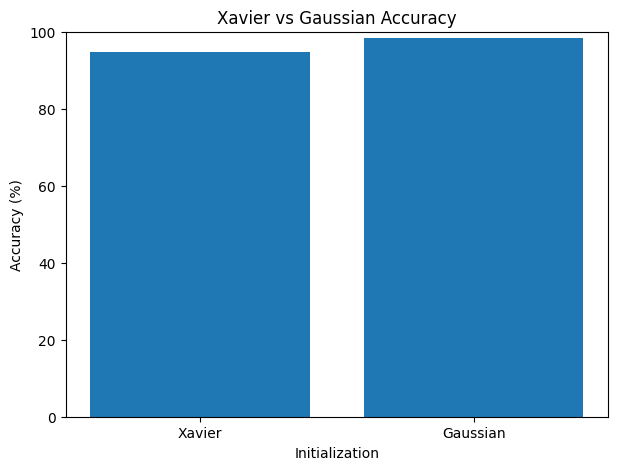


Part K


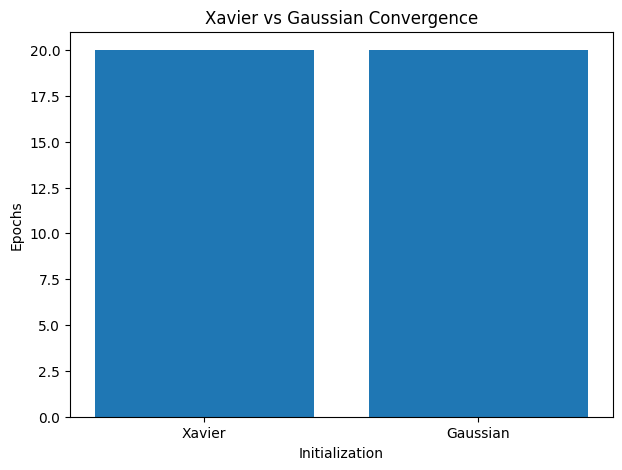

In [ ]:
data = pd.read_csv("data.csv")
X = data.drop(columns=["id","diagnosis","Unnamed: 32"],errors="ignore")
y = data["diagnosis"].map({"B":0,"M":1})
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training data shape:",X_train.shape)
print("Testing data shape:",X_test.shape)
print("\nPart B")
learning_rate = 0.01
epochs = 20
def predict(X,weights,bias):
    linear_output = np.dot(X,weights) + bias
    predictions = np.where(linear_output >= 0,1,0)
    return predictions
print("Learning rate:",learning_rate)
print("Number of epochs:",epochs)
print("\nPart C")
np.random.seed(42)
input_features = X_train.shape[1]
limit = np.sqrt(6 / input_features)
xavier_weights = np.random.uniform(-limit,limit,input_features)
xavier_bias = np.random.uniform(-limit,limit)
print("Number of input features:",input_features)
print("Xavier initialization limit:",limit)
print("Initial Xavier weights:",xavier_weights)
print("Initial Xavier bias:",xavier_bias)
print("\nPart D")
xavier_error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],xavier_weights,xavier_bias)
        error = y_train.iloc[i] - prediction
        xavier_weights += learning_rate * error * X_train[i]
        xavier_bias += learning_rate * error
        total_error += abs(error)
    xavier_error_history.append(total_error)
    print("Epoch:",epoch + 1)
    print("Training error:",total_error)
print("\nPart E")
xavier_predictions = predict(X_test,xavier_weights,xavier_bias)
xavier_accuracy = np.mean(xavier_predictions == y_test.to_numpy())
xavier_convergence_epoch = next((i + 1 for i,error in enumerate(xavier_error_history) if error == 0),epochs)
print("Xavier test accuracy:",xavier_accuracy)
print("Xavier test accuracy percentage:",xavier_accuracy * 100)
print("Xavier convergence epoch:",xavier_convergence_epoch)
print("\nPart F")
np.random.seed(42)
gaussian_mean = 0
gaussian_standard_deviation = 0.01
gaussian_weights = np.random.normal(gaussian_mean,gaussian_standard_deviation,input_features)
gaussian_bias = np.random.normal(gaussian_mean,gaussian_standard_deviation)
gaussian_error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],gaussian_weights,gaussian_bias)
        error = y_train.iloc[i] - prediction
        gaussian_weights += learning_rate * error * X_train[i]
        gaussian_bias += learning_rate * error
        total_error += abs(error)
    gaussian_error_history.append(total_error)
gaussian_predictions = predict(X_test,gaussian_weights,gaussian_bias)
gaussian_accuracy = np.mean(gaussian_predictions == y_test.to_numpy())
gaussian_convergence_epoch = next((i + 1 for i,error in enumerate(gaussian_error_history) if error == 0),epochs)
print("Gaussian test accuracy:",gaussian_accuracy)
print("Gaussian test accuracy percentage:",gaussian_accuracy * 100)
print("Gaussian convergence epoch:",gaussian_convergence_epoch)
print("\nPart G")
print("Final weights comparison:")
for i in range(len(xavier_weights)):
    print("Weight",i + 1,": Xavier =",xavier_weights[i],", Gaussian =",gaussian_weights[i])
print("Xavier final bias:",xavier_bias)
print("Gaussian final bias:",gaussian_bias)
print("\nPart H")
plt.figure(figsize=(8,5))
plt.plot(range(1,epochs + 1),xavier_error_history,marker="o",label="Xavier Initialization")
plt.plot(range(1,epochs + 1),gaussian_error_history,marker="s",label="Gaussian Initialization")
plt.title("Xavier vs Gaussian Learning Curve")
plt.xlabel("Epoch")
plt.ylabel("Training Error")
plt.legend()
plt.grid()
plt.show()
print("\nPart I")
weight_numbers = np.arange(1,input_features + 1)
plt.figure(figsize=(10,5))
plt.plot(weight_numbers,xavier_weights,marker="o",label="Xavier Initialization")
plt.plot(weight_numbers,gaussian_weights,marker="s",label="Gaussian Initialization")
plt.title("Final Weight Comparison")
plt.xlabel("Weight Number")
plt.ylabel("Weight Value")
plt.legend()
plt.grid()
plt.show()
print("\nPart J")
models = ["Xavier","Gaussian"]
accuracies = [xavier_accuracy * 100,gaussian_accuracy * 100]
plt.figure(figsize=(7,5))
plt.bar(models,accuracies)
plt.title("Xavier vs Gaussian Accuracy")
plt.xlabel("Initialization")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)
plt.show()
print("\nPart K")
convergence_epochs = [xavier_convergence_epoch,gaussian_convergence_epoch]
plt.figure(figsize=(7,5))
plt.bar(models,convergence_epochs)
plt.title("Xavier vs Gaussian Convergence")
plt.xlabel("Initialization")
plt.ylabel("Epochs")
plt.show()

Lab Task 6: He/Kaiming Initialization

Part A
Training data shape: (455, 30)
Testing data shape: (114, 30)

Part B
Learning rate: 0.01
Number of epochs: 20
Number of input features: 30

Part C
Gaussian convergence epoch: 20
Gaussian test accuracy: 0.9824561403508771
Gaussian test accuracy percentage: 98.24561403508771

Part D
Xavier convergence epoch: 20
Xavier test accuracy: 0.9473684210526315
Xavier test accuracy percentage: 94.73684210526315

Part E
He standard deviation: 0.2581988897471611
Initial He weights: [ 0.12825104 -0.03569969  0.16723246  0.39324462 -0.06045814 -0.0604539
  0.407751    0.1981508  -0.12121777  0.1400884  -0.11965393 -0.12025091
  0.06247439 -0.49400683 -0.44537187 -0.14518202 -0.26151187  0.08113831
 -0.23445081 -0.36465525  0.37842888 -0.05829519  0.01743571 -0.3678684
 -0.14055902  0.02864009 -0.29718526  0.09700481 -0.15508424 -0.075315  ]
Initial He bias: -0.15535997923115588
Epoch: 1
Training error: 43
Epoch: 2
Training error: 21
Epoch: 3
Training error: 16
Epoch: 4
Training error: 18
Epoch:

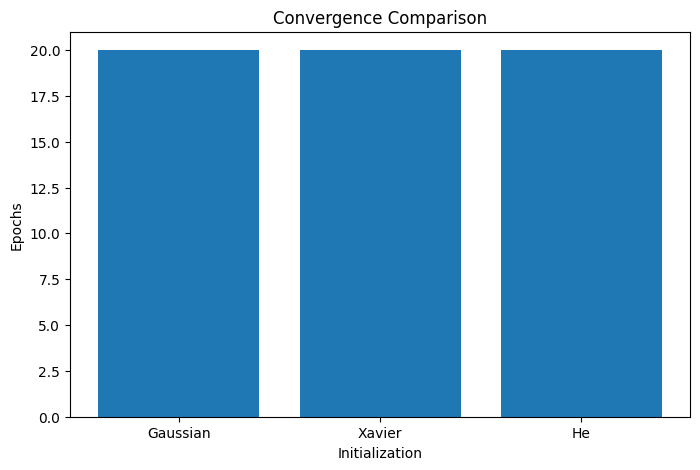


Part I


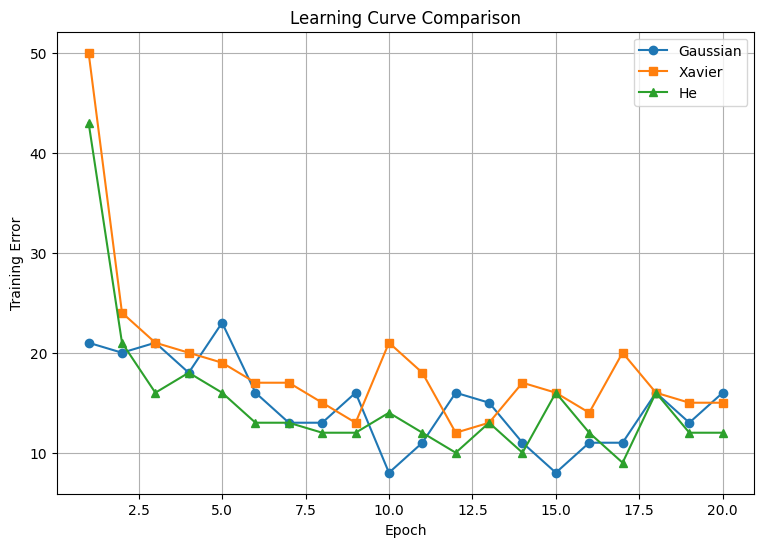


Part J


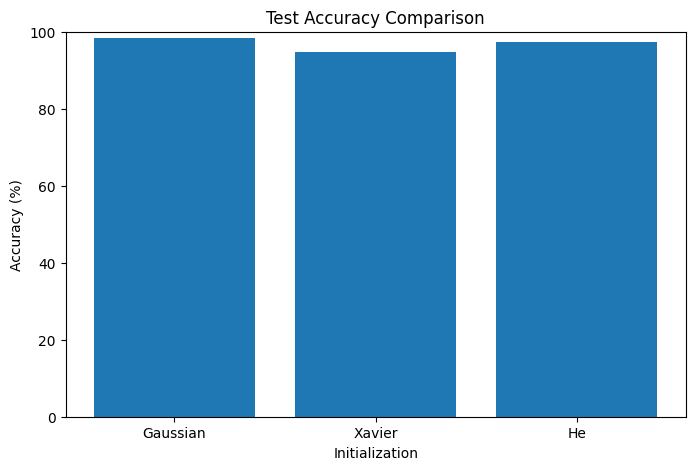


Part K


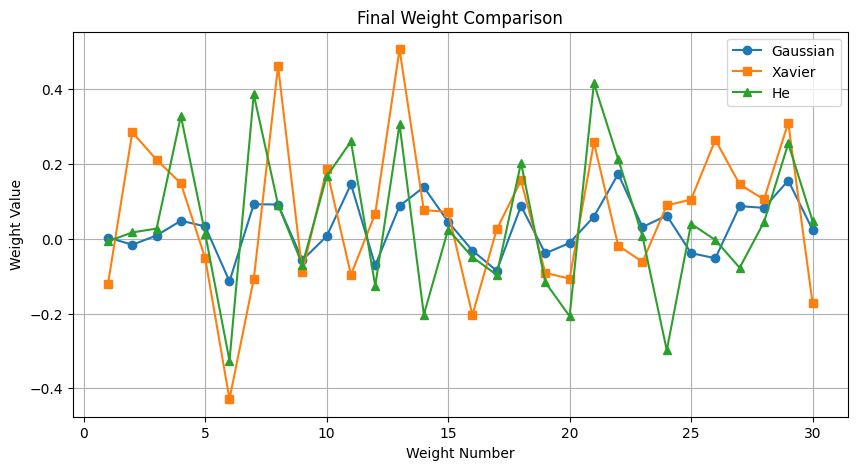

In [ ]:
data = pd.read_csv("data.csv")
X = data.drop(columns=["id","diagnosis","Unnamed: 32"],errors="ignore")
y = data["diagnosis"].map({"B":0,"M":1})
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training data shape:",X_train.shape)
print("Testing data shape:",X_test.shape)
print("\nPart B")
learning_rate = 0.01
epochs = 20
input_features = X_train.shape[1]
def predict(X,weights,bias):
    linear_output = np.dot(X,weights) + bias
    predictions = np.where(linear_output >= 0,1,0)
    return predictions
print("Learning rate:",learning_rate)
print("Number of epochs:",epochs)
print("Number of input features:",input_features)
print("\nPart C")
np.random.seed(42)
gaussian_weights = np.random.normal(0,0.01,input_features)
gaussian_bias = np.random.normal(0,0.01)
gaussian_error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],gaussian_weights,gaussian_bias)
        error = y_train.iloc[i] - prediction
        gaussian_weights += learning_rate * error * X_train[i]
        gaussian_bias += learning_rate * error
        total_error += abs(error)
    gaussian_error_history.append(total_error)
gaussian_predictions = predict(X_test,gaussian_weights,gaussian_bias)
gaussian_accuracy = np.mean(gaussian_predictions == y_test.to_numpy())
gaussian_convergence_epoch = next((i + 1 for i,error in enumerate(gaussian_error_history) if error == 0),epochs)
print("Gaussian convergence epoch:",gaussian_convergence_epoch)
print("Gaussian test accuracy:",gaussian_accuracy)
print("Gaussian test accuracy percentage:",gaussian_accuracy * 100)
print("\nPart D")
np.random.seed(42)
xavier_limit = np.sqrt(6 / input_features)
xavier_weights = np.random.uniform(-xavier_limit,xavier_limit,input_features)
xavier_bias = np.random.uniform(-xavier_limit,xavier_limit)
xavier_error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],xavier_weights,xavier_bias)
        error = y_train.iloc[i] - prediction
        xavier_weights += learning_rate * error * X_train[i]
        xavier_bias += learning_rate * error
        total_error += abs(error)
    xavier_error_history.append(total_error)
xavier_predictions = predict(X_test,xavier_weights,xavier_bias)
xavier_accuracy = np.mean(xavier_predictions == y_test.to_numpy())
xavier_convergence_epoch = next((i + 1 for i,error in enumerate(xavier_error_history) if error == 0),epochs)
print("Xavier convergence epoch:",xavier_convergence_epoch)
print("Xavier test accuracy:",xavier_accuracy)
print("Xavier test accuracy percentage:",xavier_accuracy * 100)
print("\nPart E")
np.random.seed(42)
he_standard_deviation = np.sqrt(2 / input_features)
he_weights = np.random.normal(0,he_standard_deviation,input_features)
he_bias = np.random.normal(0,he_standard_deviation)
he_error_history = []
print("He standard deviation:",he_standard_deviation)
print("Initial He weights:",he_weights)
print("Initial He bias:",he_bias)
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],he_weights,he_bias)
        error = y_train.iloc[i] - prediction
        he_weights += learning_rate * error * X_train[i]
        he_bias += learning_rate * error
        total_error += abs(error)
    he_error_history.append(total_error)
    print("Epoch:",epoch + 1)
    print("Training error:",total_error)
he_predictions = predict(X_test,he_weights,he_bias)
he_accuracy = np.mean(he_predictions == y_test.to_numpy())
he_convergence_epoch = next((i + 1 for i,error in enumerate(he_error_history) if error == 0),epochs)
print("\nPart F")
print("He convergence epoch:",he_convergence_epoch)
print("He test accuracy:",he_accuracy)
print("He test accuracy percentage:",he_accuracy * 100)
print("\nPart G")
print("Final weights comparison:")
for i in range(input_features):
    print("Weight",i + 1,": Gaussian =",gaussian_weights[i],", Xavier =",xavier_weights[i],", He =",he_weights[i])
print("Gaussian final bias:",gaussian_bias)
print("Xavier final bias:",xavier_bias)
print("He final bias:",he_bias)
print("\nPart H")
models = ["Gaussian","Xavier","He"]
convergence_epochs = [gaussian_convergence_epoch,xavier_convergence_epoch,he_convergence_epoch]
plt.figure(figsize=(8,5))
plt.bar(models,convergence_epochs)
plt.title("Convergence Comparison")
plt.xlabel("Initialization")
plt.ylabel("Epochs")
plt.show()
print("\nPart I")
plt.figure(figsize=(9,6))
plt.plot(range(1,epochs + 1),gaussian_error_history,marker="o",label="Gaussian")
plt.plot(range(1,epochs + 1),xavier_error_history,marker="s",label="Xavier")
plt.plot(range(1,epochs + 1),he_error_history,marker="^",label="He")
plt.title("Learning Curve Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Error")
plt.legend()
plt.grid()
plt.show()
print("\nPart J")
accuracies = [gaussian_accuracy * 100,xavier_accuracy * 100,he_accuracy * 100]
plt.figure(figsize=(8,5))
plt.bar(models,accuracies)
plt.title("Test Accuracy Comparison")
plt.xlabel("Initialization")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)
plt.show()
print("\nPart K")
weight_numbers = np.arange(1,input_features + 1)
plt.figure(figsize=(10,5))
plt.plot(weight_numbers,gaussian_weights,marker="o",label="Gaussian")
plt.plot(weight_numbers,xavier_weights,marker="s",label="Xavier")
plt.plot(weight_numbers,he_weights,marker="^",label="He")
plt.title("Final Weight Comparison")
plt.xlabel("Weight Number")
plt.ylabel("Weight Value")
plt.legend()
plt.grid()
plt.show()

Lab Task 7: Orthogonal Initialization

Part A
Training data shape: (455, 30)
Testing data shape: (114, 30)

Part B
Learning rate: 0.01
Number of epochs: 20
Number of input features: 30

Part C
Initial orthogonal weights: [-0.12152513  0.14721238  0.11723385 -0.02375081 -0.19353236 -0.0612851
 -0.15307457 -0.13967298  0.1938966  -0.35261916  0.20282033  0.00299627
 -0.12706232  0.21980441 -0.50417863  0.01533495  0.03129607 -0.06616945
 -0.20445883 -0.00450621 -0.18520338  0.41407515  0.14035104  0.08831329
 -0.07530619  0.22587647 -0.04347599  0.04571966  0.0121017   0.04329157]
Initial orthogonal bias: 0
Epoch: 1
Training error: 37
Epoch: 2
Training error: 20
Epoch: 3
Training error: 16
Epoch: 4
Training error: 15
Epoch: 5
Training error: 17
Epoch: 6
Training error: 13
Epoch: 7
Training error: 12
Epoch: 8
Training error: 18
Epoch: 9
Training error: 14
Epoch: 10
Training error: 13
Epoch: 11
Training error: 13
Epoch: 12
Training error: 8
Epoch: 13
Training error: 12
Epoch: 14
Training error: 13
Epoch: 15
Training error: 13
E

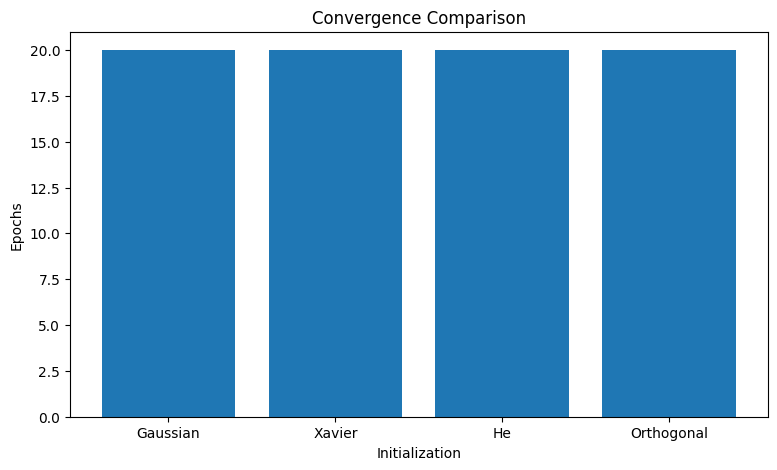


Part J


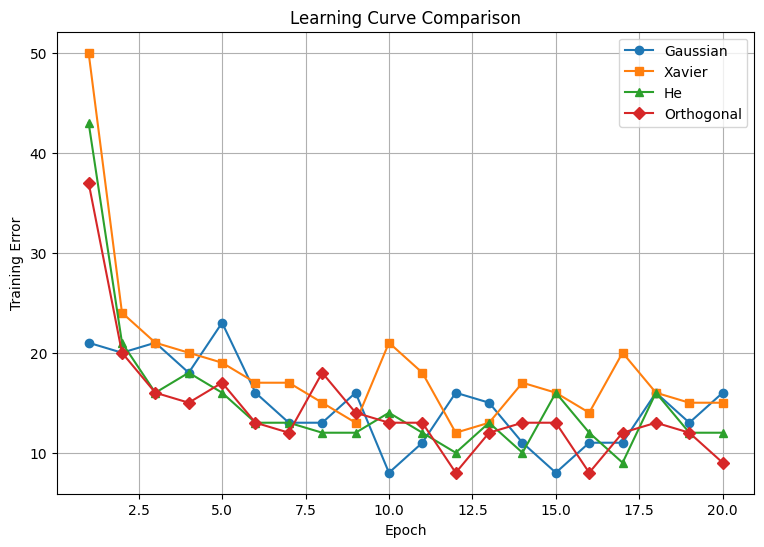


Part K


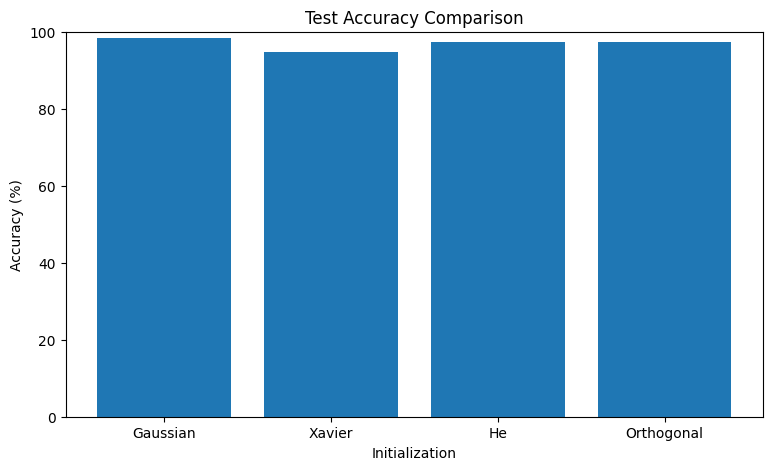


Part L


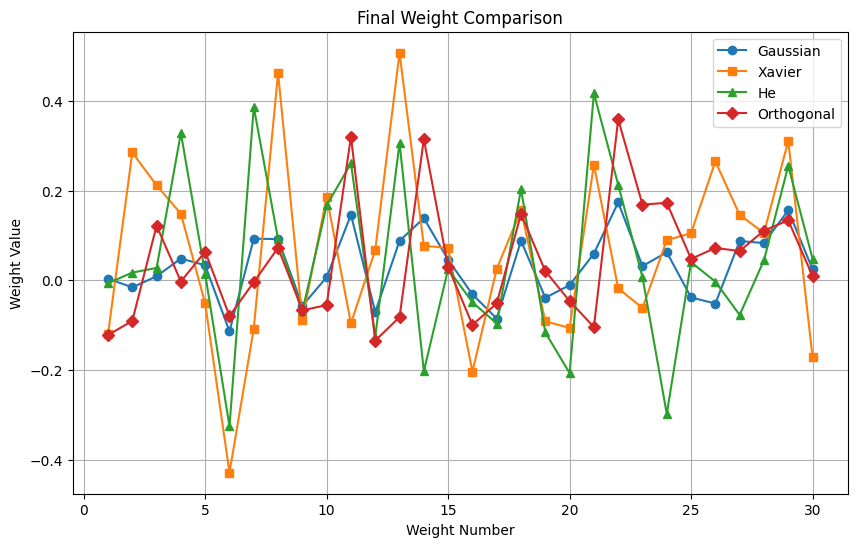

In [ ]:
data = pd.read_csv("data.csv")
X = data.drop(columns=["id","diagnosis","Unnamed: 32"],errors="ignore")
y = data["diagnosis"].map({"B":0,"M":1})
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training data shape:",X_train.shape)
print("Testing data shape:",X_test.shape)
print("\nPart B")
learning_rate = 0.01
epochs = 20
input_features = X_train.shape[1]
def predict(X,weights,bias):
    linear_output = np.dot(X,weights) + bias
    predictions = np.where(linear_output >= 0,1,0)
    return predictions
print("Learning rate:",learning_rate)
print("Number of epochs:",epochs)
print("Number of input features:",input_features)
print("\nPart C")
np.random.seed(42)
random_matrix = np.random.normal(0,1,(input_features,input_features))
Q,R = np.linalg.qr(random_matrix)
orthogonal_weights = Q[:,0]
orthogonal_bias = 0
orthogonal_error_history = []
print("Initial orthogonal weights:",orthogonal_weights)
print("Initial orthogonal bias:",orthogonal_bias)
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],orthogonal_weights,orthogonal_bias)
        error = y_train.iloc[i] - prediction
        orthogonal_weights += learning_rate * error * X_train[i]
        orthogonal_bias += learning_rate * error
        total_error += abs(error)
    orthogonal_error_history.append(total_error)
    print("Epoch:",epoch + 1)
    print("Training error:",total_error)
orthogonal_predictions = predict(X_test,orthogonal_weights,orthogonal_bias)
orthogonal_accuracy = np.mean(orthogonal_predictions == y_test.to_numpy())
orthogonal_convergence_epoch = next((i + 1 for i,error in enumerate(orthogonal_error_history) if error == 0),epochs)
print("\nPart D")
print("Orthogonal convergence epoch:",orthogonal_convergence_epoch)
print("Orthogonal test accuracy:",orthogonal_accuracy)
print("Orthogonal test accuracy percentage:",orthogonal_accuracy * 100)
print("\nPart E")
np.random.seed(42)
gaussian_weights = np.random.normal(0,0.01,input_features)
gaussian_bias = np.random.normal(0,0.01)
gaussian_error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],gaussian_weights,gaussian_bias)
        error = y_train.iloc[i] - prediction
        gaussian_weights += learning_rate * error * X_train[i]
        gaussian_bias += learning_rate * error
        total_error += abs(error)
    gaussian_error_history.append(total_error)
gaussian_predictions = predict(X_test,gaussian_weights,gaussian_bias)
gaussian_accuracy = np.mean(gaussian_predictions == y_test.to_numpy())
gaussian_convergence_epoch = next((i + 1 for i,error in enumerate(gaussian_error_history) if error == 0),epochs)
print("Gaussian convergence epoch:",gaussian_convergence_epoch)
print("Gaussian test accuracy:",gaussian_accuracy)
print("Gaussian test accuracy percentage:",gaussian_accuracy * 100)
print("\nPart F")
np.random.seed(42)
xavier_limit = np.sqrt(6 / input_features)
xavier_weights = np.random.uniform(-xavier_limit,xavier_limit,input_features)
xavier_bias = np.random.uniform(-xavier_limit,xavier_limit)
xavier_error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],xavier_weights,xavier_bias)
        error = y_train.iloc[i] - prediction
        xavier_weights += learning_rate * error * X_train[i]
        xavier_bias += learning_rate * error
        total_error += abs(error)
    xavier_error_history.append(total_error)
xavier_predictions = predict(X_test,xavier_weights,xavier_bias)
xavier_accuracy = np.mean(xavier_predictions == y_test.to_numpy())
xavier_convergence_epoch = next((i + 1 for i,error in enumerate(xavier_error_history) if error == 0),epochs)
print("Xavier convergence epoch:",xavier_convergence_epoch)
print("Xavier test accuracy:",xavier_accuracy)
print("Xavier test accuracy percentage:",xavier_accuracy * 100)
print("\nPart G")
np.random.seed(42)
he_standard_deviation = np.sqrt(2 / input_features)
he_weights = np.random.normal(0,he_standard_deviation,input_features)
he_bias = np.random.normal(0,he_standard_deviation)
he_error_history = []
for epoch in range(epochs):
    total_error = 0
    for i in range(len(X_train)):
        prediction = predict(X_train[i],he_weights,he_bias)
        error = y_train.iloc[i] - prediction
        he_weights += learning_rate * error * X_train[i]
        he_bias += learning_rate * error
        total_error += abs(error)
    he_error_history.append(total_error)
he_predictions = predict(X_test,he_weights,he_bias)
he_accuracy = np.mean(he_predictions == y_test.to_numpy())
he_convergence_epoch = next((i + 1 for i,error in enumerate(he_error_history) if error == 0),epochs)
print("He convergence epoch:",he_convergence_epoch)
print("He test accuracy:",he_accuracy)
print("He test accuracy percentage:",he_accuracy * 100)
print("\nPart H")
print("Final weights comparison:")
for i in range(input_features):
    print("Weight",i + 1,": Gaussian =",gaussian_weights[i],", Xavier =",xavier_weights[i],", He =",he_weights[i],", Orthogonal =",orthogonal_weights[i])
print("Gaussian final bias:",gaussian_bias)
print("Xavier final bias:",xavier_bias)
print("He final bias:",he_bias)
print("Orthogonal final bias:",orthogonal_bias)
print("\nPart I")
models = ["Gaussian","Xavier","He","Orthogonal"]
convergence_epochs = [gaussian_convergence_epoch,xavier_convergence_epoch,he_convergence_epoch,orthogonal_convergence_epoch]
plt.figure(figsize=(9,5))
plt.bar(models,convergence_epochs)
plt.title("Convergence Comparison")
plt.xlabel("Initialization")
plt.ylabel("Epochs")
plt.show()
print("\nPart J")
plt.figure(figsize=(9,6))
plt.plot(range(1,epochs + 1),gaussian_error_history,marker="o",label="Gaussian")
plt.plot(range(1,epochs + 1),xavier_error_history,marker="s",label="Xavier")
plt.plot(range(1,epochs + 1),he_error_history,marker="^",label="He")
plt.plot(range(1,epochs + 1),orthogonal_error_history,marker="D",label="Orthogonal")
plt.title("Learning Curve Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Error")
plt.legend()
plt.grid()
plt.show()
print("\nPart K")
accuracies = [gaussian_accuracy * 100,xavier_accuracy * 100,he_accuracy * 100,orthogonal_accuracy * 100]
plt.figure(figsize=(9,5))
plt.bar(models,accuracies)
plt.title("Test Accuracy Comparison")
plt.xlabel("Initialization")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)
plt.show()
print("\nPart L")
weight_numbers = np.arange(1,input_features + 1)
plt.figure(figsize=(10,6))
plt.plot(weight_numbers,gaussian_weights,marker="o",label="Gaussian")
plt.plot(weight_numbers,xavier_weights,marker="s",label="Xavier")
plt.plot(weight_numbers,he_weights,marker="^",label="He")
plt.plot(weight_numbers,orthogonal_weights,marker="D",label="Orthogonal")
plt.title("Final Weight Comparison")
plt.xlabel("Weight Number")
plt.ylabel("Weight Value")
plt.legend()
plt.grid()
plt.show()

Lab Task 8: Comparative Analysis of Weight Initialization Techniques

Part A
Training data shape: (455, 30)
Testing data shape: (114, 30)

Part B
Learning rate: 0.01
Number of epochs: 20
Number of input features: 30

Part C
Gaussian weights initialized
Xavier weights initialized
He weights initialized
Orthogonal weights initialized

Part D
Training completed for all initialization techniques

Part E
Convergence and performance comparison:
Gaussian
Convergence epoch: 20
Final training error: 16
Test accuracy: 0.9824561403508771
Test accuracy percentage: 98.24561403508771
Xavier
Convergence epoch: 20
Final training error: 13
Test accuracy: 0.9736842105263158
Test accuracy percentage: 97.36842105263158
He
Convergence epoch: 20
Final training error: 10
Test accuracy: 0.956140350877193
Test accuracy percentage: 95.6140350877193
Orthogonal
Convergence epoch: 20
Final training error: 9
Test accuracy: 0.9736842105263158
Test accuracy percentage: 97.36842105263158

Part F
Final weights:

 Gaussian weights:
Weight 1 : 0.0035670910607775042
Weight 2 : -0.0158808694

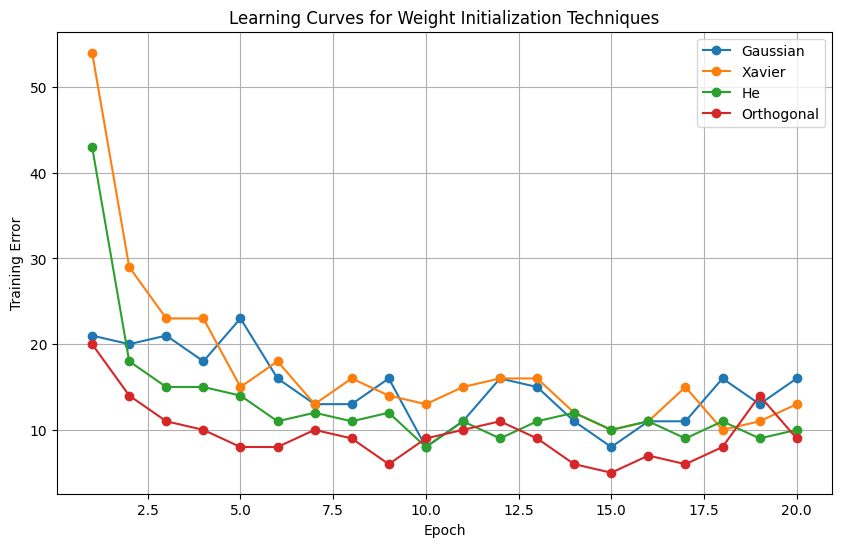


Part H


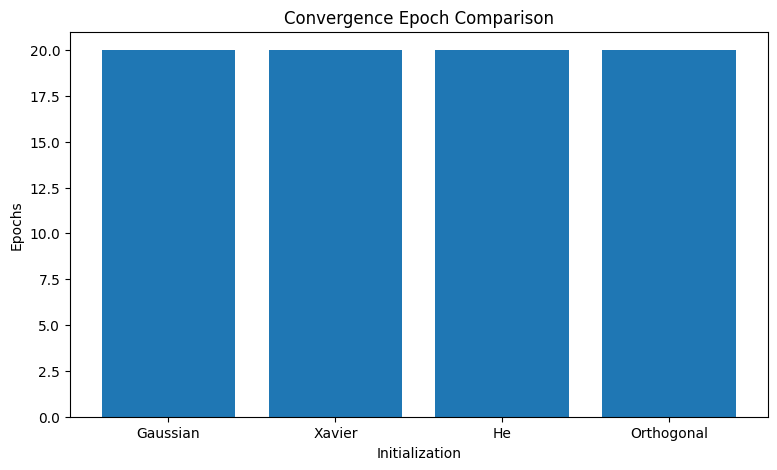


Part I


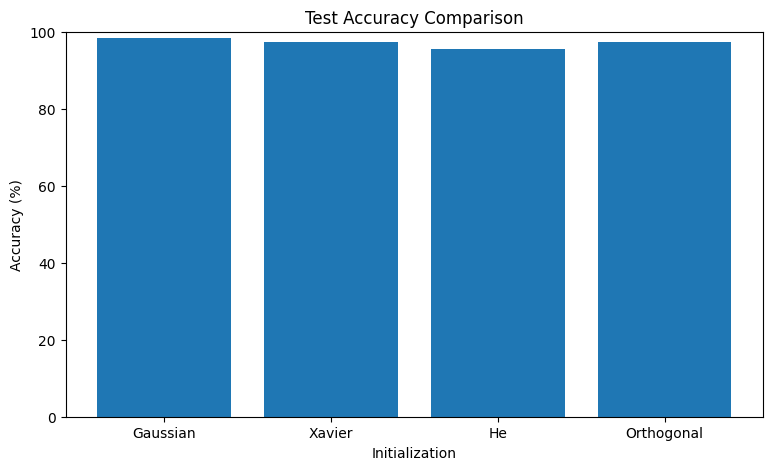


Part J


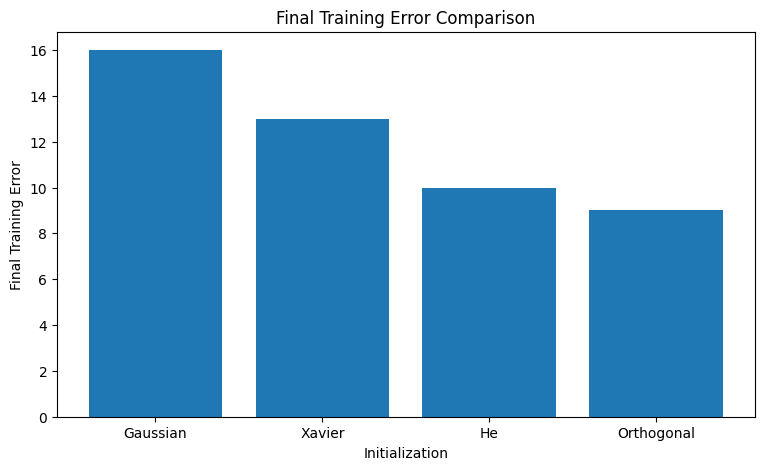


Part K


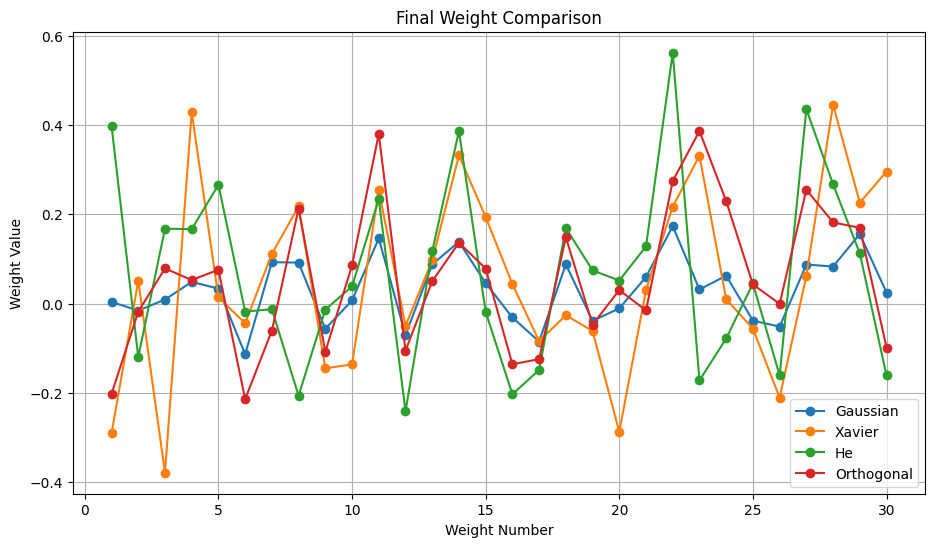


Part L
Analysis
Different initialization techniques start the perceptron with different weight values.
These starting values can affect the number of updates required during training.
Gaussian initialization uses small random values, while Xavier and He use ranges based on the number of input features.
Orthogonal initialization starts with a normalized orthogonal weight vector.
The learning curves show how quickly the training error changes for each initialization.
Differences in convergence and final weights are caused by the different starting points of the models.
The final test accuracy shows how each initialization performed on unseen test data.


In [ ]:
data = pd.read_csv("data.csv")
X = data.drop(columns=["id","diagnosis","Unnamed: 32"],errors="ignore")
y = data["diagnosis"].map({"B":0,"M":1})
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training data shape:",X_train.shape)
print("Testing data shape:",X_test.shape)

print("\nPart B")
learning_rate = 0.01
epochs = 20
input_features = X_train.shape[1]
def predict(X,weights,bias):
    linear_output = np.dot(X,weights) + bias
    predictions = np.where(linear_output >= 0,1,0)
    return predictions
print("Learning rate:",learning_rate)
print("Number of epochs:",epochs)
print("Number of input features:",input_features)

print("\nPart C")
np.random.seed(42)
gaussian_weights = np.random.normal(0,0.01,input_features)
gaussian_bias = np.random.normal(0,0.01)
xavier_limit = np.sqrt(6 / input_features)
xavier_weights = np.random.uniform(-xavier_limit,xavier_limit,input_features)
xavier_bias = np.random.uniform(-xavier_limit,xavier_limit)
he_standard_deviation = np.sqrt(2 / input_features)
he_weights = np.random.normal(0,he_standard_deviation,input_features)
he_bias = np.random.normal(0,he_standard_deviation)
random_matrix = np.random.normal(0,1,(input_features,input_features))
Q,R = np.linalg.qr(random_matrix)
orthogonal_weights = Q[:,0]
orthogonal_bias = 0
print("Gaussian weights initialized")
print("Xavier weights initialized")
print("He weights initialized")
print("Orthogonal weights initialized")

print("\nPart D")
initializations = {
    "Gaussian":(gaussian_weights,gaussian_bias),
    "Xavier":(xavier_weights,xavier_bias),
    "He":(he_weights,he_bias),
    "Orthogonal":(orthogonal_weights,orthogonal_bias)
}
error_histories = {}
final_weights = {}
final_biases = {}
convergence_epochs = {}
test_accuracies = {}
final_training_errors = {}
for name,(weights,bias) in initializations.items():
    error_history = []
    for epoch in range(epochs):
        total_error = 0
        for i in range(len(X_train)):
            prediction = predict(X_train[i],weights,bias)
            error = y_train.iloc[i] - prediction
            weights += learning_rate * error * X_train[i]
            bias += learning_rate * error
            total_error += abs(error)
        error_history.append(total_error)
    predictions = predict(X_test,weights,bias)
    accuracy = np.mean(predictions == y_test.to_numpy())
    convergence_epoch = next((i + 1 for i,error in enumerate(error_history) if error == 0),epochs)
    error_histories[name] = error_history
    final_weights[name] = weights.copy()
    final_biases[name] = bias
    convergence_epochs[name] = convergence_epoch
    test_accuracies[name] = accuracy
    final_training_errors[name] = error_history[-1]
print("Training completed for all initialization techniques")

print("\nPart E")
print("Convergence and performance comparison:")
for name in initializations:
    print(name)
    print("Convergence epoch:",convergence_epochs[name])
    print("Final training error:",final_training_errors[name])
    print("Test accuracy:",test_accuracies[name])
    print("Test accuracy percentage:",test_accuracies[name] * 100)

print("\nPart F")
print("Final weights:")
for name in initializations:
    print("\n",name,"weights:")
    for i in range(input_features):
        print("Weight",i + 1,":",final_weights[name][i])
    print("Final bias:",final_biases[name])

print("\nPart G")
plt.figure(figsize=(10,6))
for name in initializations:
    plt.plot(range(1,epochs + 1),error_histories[name],marker="o",label=name)
plt.title("Learning Curves for Weight Initialization Techniques")
plt.xlabel("Epoch")
plt.ylabel("Training Error")
plt.legend()
plt.grid()
plt.show()

print("\nPart H")
models = list(initializations.keys())
convergence_values = [convergence_epochs[name] for name in models]
plt.figure(figsize=(9,5))
plt.bar(models,convergence_values)
plt.title("Convergence Epoch Comparison")
plt.xlabel("Initialization")
plt.ylabel("Epochs")
plt.show()

print("\nPart I")
accuracy_values = [test_accuracies[name] * 100 for name in models]
plt.figure(figsize=(9,5))
plt.bar(models,accuracy_values)
plt.title("Test Accuracy Comparison")
plt.xlabel("Initialization")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)
plt.show()

print("\nPart J")
training_error_values = [final_training_errors[name] for name in models]
plt.figure(figsize=(9,5))
plt.bar(models,training_error_values)
plt.title("Final Training Error Comparison")
plt.xlabel("Initialization")
plt.ylabel("Final Training Error")
plt.show()

print("\nPart K")
weight_numbers = np.arange(1,input_features + 1)
plt.figure(figsize=(11,6))
for name in initializations:
    plt.plot(weight_numbers,final_weights[name],marker="o",label=name)
plt.title("Final Weight Comparison")
plt.xlabel("Weight Number")
plt.ylabel("Weight Value")
plt.legend()
plt.grid()
plt.show()

print("\nPart L")
print("Analysis")
print("Different initialization techniques start the perceptron with different weight values.")
print("These starting values can affect the number of updates required during training.")
print("Gaussian initialization uses small random values, while Xavier and He use ranges based on the number of input features.")
print("Orthogonal initialization starts with a normalized orthogonal weight vector.")
print("The learning curves show how quickly the training error changes for each initialization.")
print("Differences in convergence and final weights are caused by the different starting points of the models.")
print("The final test accuracy shows how each initialization performed on unseen test data.")


Lab Task 9: Experimental Study and Interpretation

In [23]:
from sklearn.datasets import load_iris

Part A
Dataset shape: (100, 6)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target variable: target
Class distribution:
target
0    50
1    50
Name: count, dtype: int64

Part B
Learning rate: 0.01
Number of epochs: 20
Random seeds: [10, 20, 30, 40, 50]
Number of input features: 4

Part C

Random seed: 10
Gaussian
Convergence epoch: 2
Test accuracy: 100.0
Xavier
Convergence epoch: 3
Test accuracy: 100.0
He
Convergence epoch: 6
Test accuracy: 90.0
Orthogonal
Convergence epoch: 8
Test accuracy: 100.0

Random seed: 20
Gaussian
Convergence epoch: 2
Test accuracy: 100.0
Xavier
Convergence epoch: 12
Test accuracy: 100.0
He
Convergence epoch: 14
Test accuracy: 100.0
Orthogonal
Convergence epoch: 8
Test accuracy: 100.0

Random seed: 30
Gaussian
Convergence epoch: 2
Test accuracy: 100.0
Xavier
Convergence epoch: 7
Test accuracy: 100.0
He
Convergence epoch: 10
Test accuracy: 100.0
Orthogonal
Convergence epoch: 5
Test accuracy: 100.0

Random seed: 40

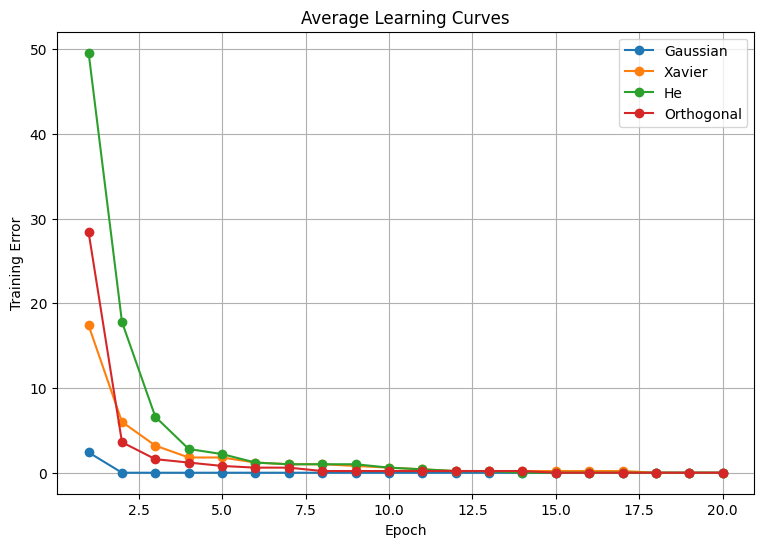


Part F


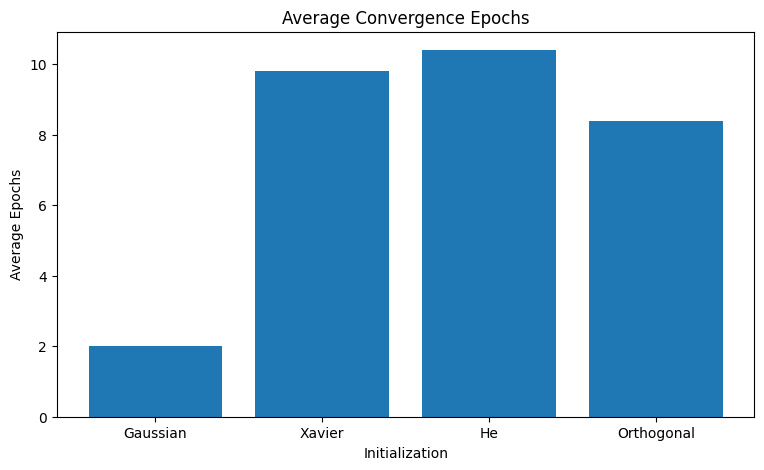


Part G


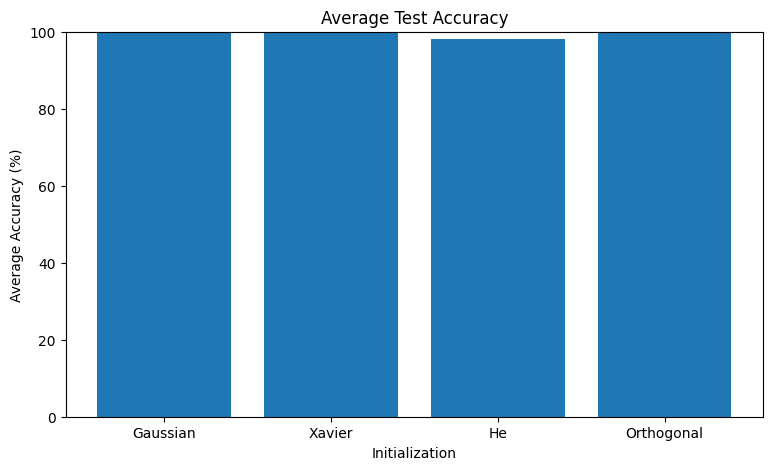


Part H
Experimental Analysis
The Iris dataset contains two classes in this experiment: Setosa and Versicolor.
Multiple random seeds were used to observe the effect of randomness.
Different initialization techniques start the perceptron with different weight values.
Gaussian initialization starts with small random weights.
Xavier initialization uses a range based on the number of input features.
He initialization uses a standard deviation based on the number of input features.
Orthogonal initialization starts with a normalized orthogonal weight vector.
The average convergence epochs show how the initialization affected the training process.
The average test accuracy shows the performance across different random runs.
Dataset characteristics can also affect perceptron training.
The Iris Setosa and Versicolor classes have relatively simple feature patterns, which can make them easier for a perceptron to separate.
Random train-test splits can change the samples seen during training and te

In [25]:
print("Part A")
iris = load_iris()
data = pd.DataFrame(iris.data,columns=iris.feature_names)
data["target"] = iris.target
data["target_name"] = iris.target_names[iris.target]
data = data[data["target_name"].isin(["setosa","versicolor"])].copy()
X = data.drop(columns=["target","target_name"])
y = data["target"].map({0:0,1:1})
print("Dataset shape:",data.shape)
print("Features:",X.columns.tolist())
print("Target variable: target")
print("Class distribution:")
print(y.value_counts())

print("\nPart B")
learning_rate = 0.01
epochs = 20
seeds = [10,20,30,40,50]
input_features = X.shape[1]
print("Learning rate:",learning_rate)
print("Number of epochs:",epochs)
print("Random seeds:",seeds)
print("Number of input features:",input_features)
def predict(X,weights,bias):
    linear_output = np.dot(X,weights) + bias
    predictions = np.where(linear_output >= 0,1,0)
    return predictions

print("\nPart C")
results = {
    "Gaussian":{"epochs":[],"accuracy":[]},
    "Xavier":{"epochs":[],"accuracy":[]},
    "He":{"epochs":[],"accuracy":[]},
    "Orthogonal":{"epochs":[],"accuracy":[]}
}
learning_curves = {
    "Gaussian":[],
    "Xavier":[],
    "He":[],
    "Orthogonal":[]
}
for seed in seeds:
    X_train,X_test,y_train,y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=seed,
        stratify=y
    )
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    print("\nRandom seed:",seed)
    for name in results:
        np.random.seed(seed)
        if name == "Gaussian":
            weights = np.random.normal(0,0.01,input_features)
            bias = np.random.normal(0,0.01)
        elif name == "Xavier":
            limit = np.sqrt(6 / input_features)
            weights = np.random.uniform(-limit,limit,input_features)
            bias = np.random.uniform(-limit,limit)
        elif name == "He":
            standard_deviation = np.sqrt(2 / input_features)
            weights = np.random.normal(0,standard_deviation,input_features)
            bias = np.random.normal(0,standard_deviation)
        else:
            random_matrix = np.random.normal(0,1,(input_features,input_features))
            Q,R = np.linalg.qr(random_matrix)
            weights = Q[:,0]
            bias = 0
        error_history = []
        for epoch in range(epochs):
            total_error = 0
            for i in range(len(X_train)):
                prediction = predict(X_train[i],weights,bias)
                error = y_train.iloc[i] - prediction
                weights += learning_rate * error * X_train[i]
                bias += learning_rate * error
                total_error += abs(error)
            error_history.append(total_error)
        predictions = predict(X_test,weights,bias)
        accuracy = np.mean(predictions == y_test.to_numpy())
        convergence_epoch = next(
            (i + 1 for i,error in enumerate(error_history) if error == 0),
            epochs
        )
        results[name]["epochs"].append(convergence_epoch)
        results[name]["accuracy"].append(accuracy)
        learning_curves[name].append(error_history)
        print(name)
        print("Convergence epoch:",convergence_epoch)
        print("Test accuracy:",accuracy * 100)

print("\nPart D")
average_epochs = {}
average_accuracy = {}
for name in results:
    average_epochs[name] = np.mean(results[name]["epochs"])
    average_accuracy[name] = np.mean(results[name]["accuracy"]) * 100
    print(name)
    print("Convergence epochs:",results[name]["epochs"])
    print("Average convergence epochs:",average_epochs[name])
    print("Test accuracies:",results[name]["accuracy"])
    print("Average test accuracy:",average_accuracy[name])

print("\nPart E")
models = list(results.keys())
plt.figure(figsize=(9,6))
for name in models:
    average_curve = np.mean(learning_curves[name],axis=0)
    plt.plot(
        range(1,epochs + 1),
        average_curve,
        marker="o",
        label=name
    )
plt.title("Average Learning Curves")
plt.xlabel("Epoch")
plt.ylabel("Training Error")
plt.legend()
plt.grid()
plt.show()

print("\nPart F")
epoch_values = [average_epochs[name] for name in models]
plt.figure(figsize=(9,5))
plt.bar(models,epoch_values)
plt.title("Average Convergence Epochs")
plt.xlabel("Initialization")
plt.ylabel("Average Epochs")
plt.show()

print("\nPart G")
accuracy_values = [average_accuracy[name] for name in models]
plt.figure(figsize=(9,5))
plt.bar(models,accuracy_values)
plt.title("Average Test Accuracy")
plt.xlabel("Initialization")
plt.ylabel("Average Accuracy (%)")
plt.ylim(0,100)
plt.show()

print("\nPart H")
print("Experimental Analysis")
print("The Iris dataset contains two classes in this experiment: Setosa and Versicolor.")
print("Multiple random seeds were used to observe the effect of randomness.")
print("Different initialization techniques start the perceptron with different weight values.")
print("Gaussian initialization starts with small random weights.")
print("Xavier initialization uses a range based on the number of input features.")
print("He initialization uses a standard deviation based on the number of input features.")
print("Orthogonal initialization starts with a normalized orthogonal weight vector.")
print("The average convergence epochs show how the initialization affected the training process.")
print("The average test accuracy shows the performance across different random runs.")
print("Dataset characteristics can also affect perceptron training.")
print("The Iris Setosa and Versicolor classes have relatively simple feature patterns, which can make them easier for a perceptron to separate.")
print("Random train-test splits can change the samples seen during training and testing.")
print("Random initialization can also change the starting point of the weight vector.")
print("Therefore, multiple runs provide a more reliable view of the training behavior than a single run.")
